# 14 — SGD Classifier

**Algorithm:** Stochastic Gradient Descent Classifier (modified Huber loss)  
**Features:** TF-IDF (50K unigrams + bigrams)  
SGD minimises a loss function using online gradient updates — ideal for large datasets. Modified Huber loss is a smooth, outlier-robust surrogate that also supports probability estimates.

In [1]:
import os, sys, time, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')
sys.path.insert(0, os.path.abspath(os.path.join(os.getcwd(), '..')))
from utils import (setup_paths, evaluate_and_print, plot_confusion_matrix,
                   plot_roc_curve, plot_pr_curve)
from sklearn.metrics import accuracy_score, log_loss
BASE_DIR, FIGURES_DIR = setup_paths()

In [2]:
from preprocess import load_all_datasets, get_train_test_split
df = load_all_datasets()
X_train, X_test, y_train, y_test = get_train_test_split(df)
from sklearn.feature_extraction.text import TfidfVectorizer
tfidf = TfidfVectorizer(max_features=50000, ngram_range=(1,2), sublinear_tf=True, min_df=2, max_df=0.95)
X_tr = tfidf.fit_transform(X_train)
X_te = tfidf.transform(X_test)
print(f'Train: {len(X_train):,}  |  Test: {len(X_test):,}')


  LOADING ALL DATASETS
  [1/5] Loading ISOT Dataset...
      Loaded 44,898 records  (Fake=23,481  Real=21,417)
  [2/5] Loading FakeNewsNet Dataset...
      Loaded 23,196 records  (Fake=5,755  Real=17,441)
  [3/5] Loading LIAR Dataset...
      Loaded 12,791 records  (Fake=5,657  Real=7,134)
  [4/5] Loading MultiFC Dataset...
      Loaded 31,921 records  (Fake=13,980  Real=17,941)
  [5/5] Loading BuzzFeed Dataset...
      Loaded 2,282 records  (Fake=613  Real=1,669)

  Combined total   : 115,088 records
  Fake (0)         : 49,486
  Real (1)         : 65,602

  Cleaning text...
  After clean+dedup: 104,521 records

  Source distribution:
source
ISOT           38826
MultiFC        31919
FakeNewsNet    21046
LIAR           12726
BuzzFeed           4
Train: 83,616  |  Test: 20,905


## Training Convergence via partial_fit (Online Learning)

In [3]:
from sklearn.linear_model import SGDClassifier
MODEL_NAME = 'SGD Classifier'

# Track convergence epoch-by-epoch using partial_fit
classes = np.unique(y_train)
n_epochs = 30
batch_size = 2048
tr_accs, te_accs, epoch_list = [], [], []

sgd_partial = SGDClassifier(loss='modified_huber', random_state=42, n_jobs=-1)
n = X_tr.shape[0]
for epoch in range(1, n_epochs + 1):
    idx = np.random.permutation(n)
    for start in range(0, n, batch_size):
        batch = idx[start:start + batch_size]
        sgd_partial.partial_fit(X_tr[batch], y_train[batch], classes=classes)
    tr_accs.append(accuracy_score(y_train, sgd_partial.predict(X_tr)))
    te_accs.append(accuracy_score(y_test,  sgd_partial.predict(X_te)))
    epoch_list.append(epoch)
    if epoch % 5 == 0:
        print(f'  Epoch {epoch:>2}: Train={tr_accs[-1]:.4f}  Test={te_accs[-1]:.4f}')

  Epoch  5: Train=0.8863  Test=0.8303
  Epoch 10: Train=0.8846  Test=0.8310
  Epoch 15: Train=0.8851  Test=0.8316
  Epoch 20: Train=0.8854  Test=0.8311
  Epoch 25: Train=0.8843  Test=0.8306
  Epoch 30: Train=0.8852  Test=0.8320


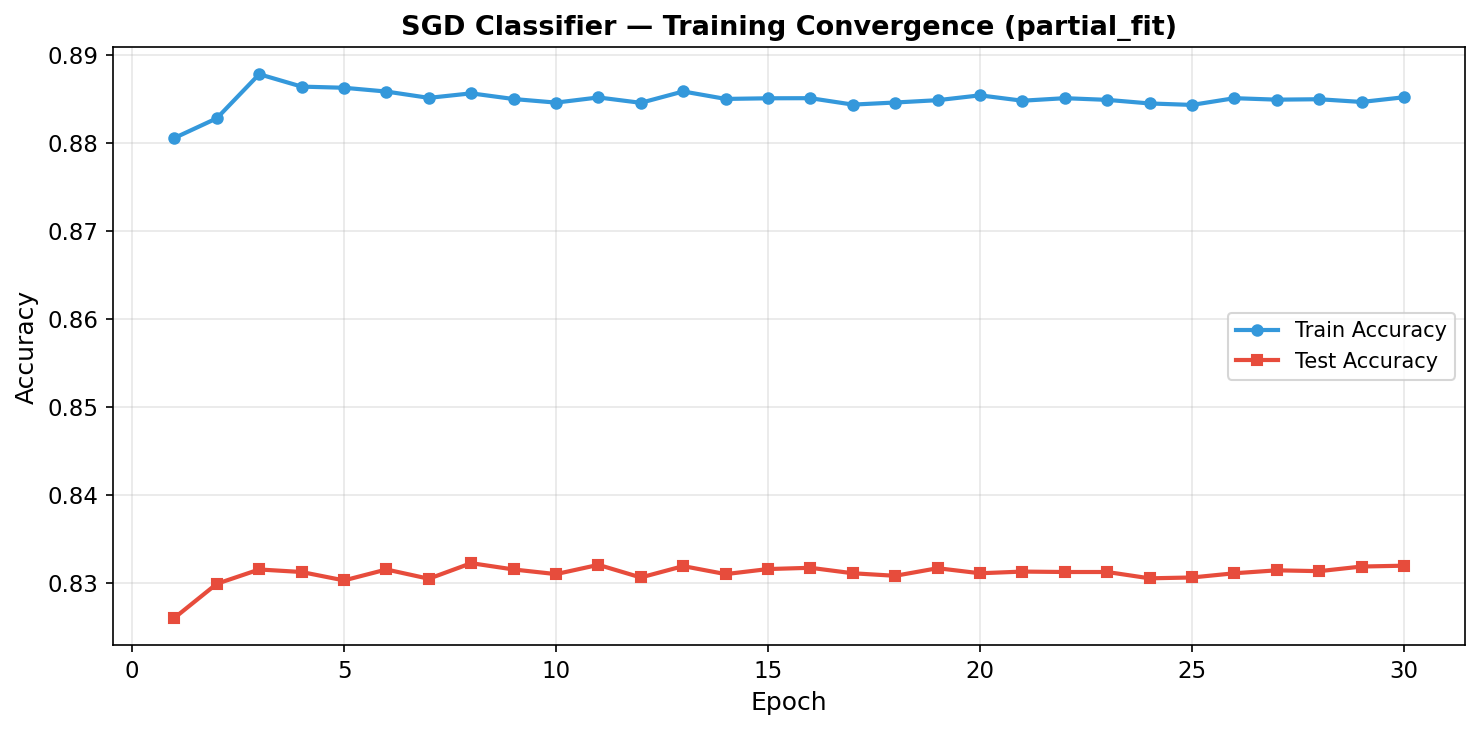

In [4]:
fig, ax = plt.subplots(figsize=(10, 5))
ax.plot(epoch_list, tr_accs, 'o-', color='#3498db', lw=2, ms=5, label='Train Accuracy')
ax.plot(epoch_list, te_accs, 's-', color='#e74c3c', lw=2, ms=5, label='Test Accuracy')
ax.set_xlabel('Epoch')
ax.set_ylabel('Accuracy')
ax.set_title('SGD Classifier — Training Convergence (partial_fit)')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'sgd_convergence.png'), dpi=150, bbox_inches='tight')
plt.show()

## Final Model (Full Training)

In [5]:
t0 = time.time()
model = SGDClassifier(loss='modified_huber', max_iter=1000, random_state=42, n_jobs=-1)
model.fit(X_tr, y_train)
train_time = time.time() - t0
print(f'Training completed in {train_time:.2f}s')
metrics, y_pred, y_prob = evaluate_and_print(model, X_te, y_test, MODEL_NAME, train_time)

Training completed in 0.92s

  SGD Classifier — Evaluation Results
  Accuracy          : 0.8314
  Precision         : 0.8314
  Recall            : 0.8314
  F1 Score          : 0.8294
  AUC-ROC           : 0.9182
  Train Time (s)    : 0.92s

              precision    recall  f1-score   support

    Fake (0)       0.83      0.74      0.78      8532
    Real (1)       0.83      0.90      0.86     12373

    accuracy                           0.83     20905
   macro avg       0.83      0.82      0.82     20905
weighted avg       0.83      0.83      0.83     20905



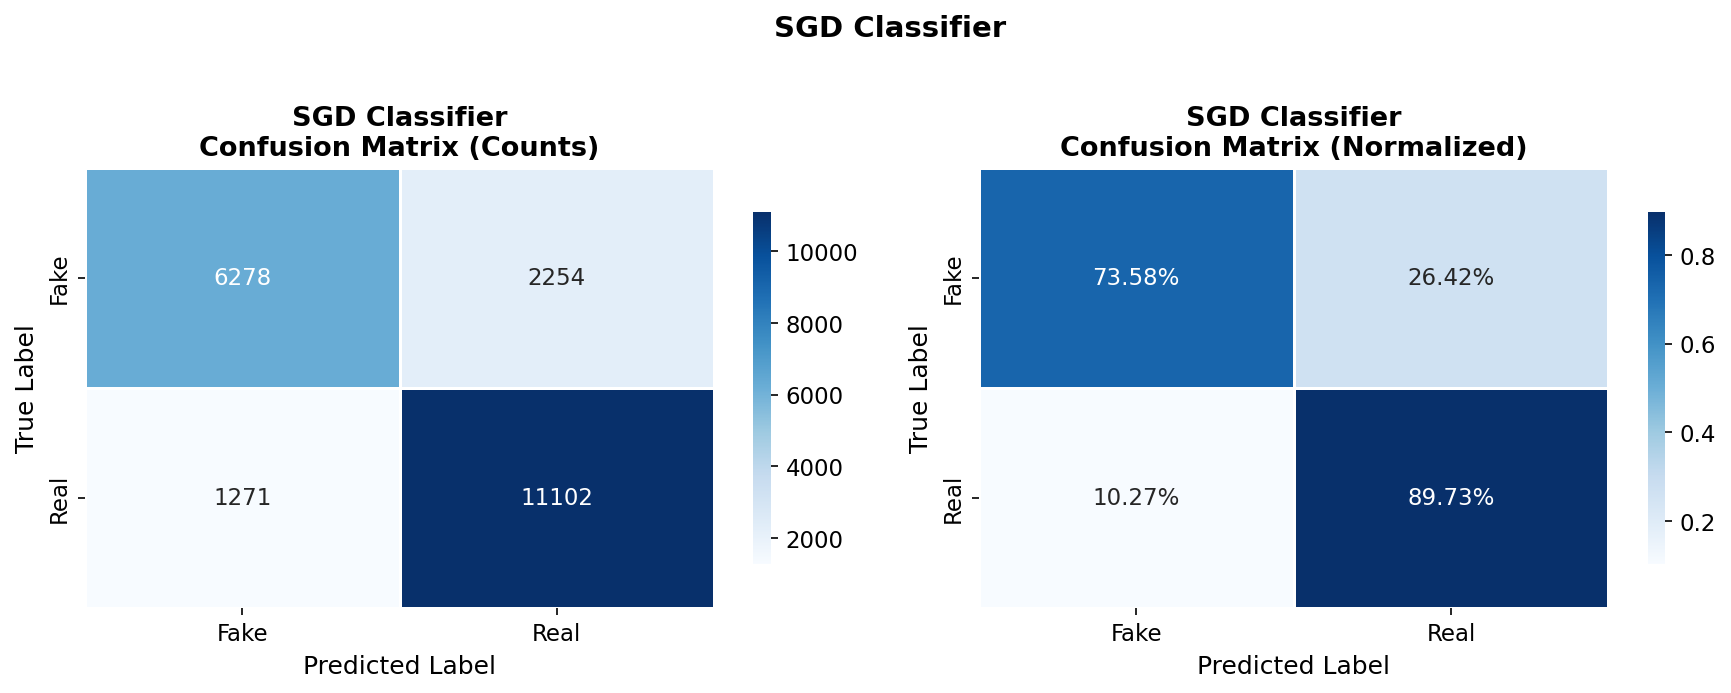

In [6]:
plot_confusion_matrix(y_test, y_pred, MODEL_NAME, FIGURES_DIR)

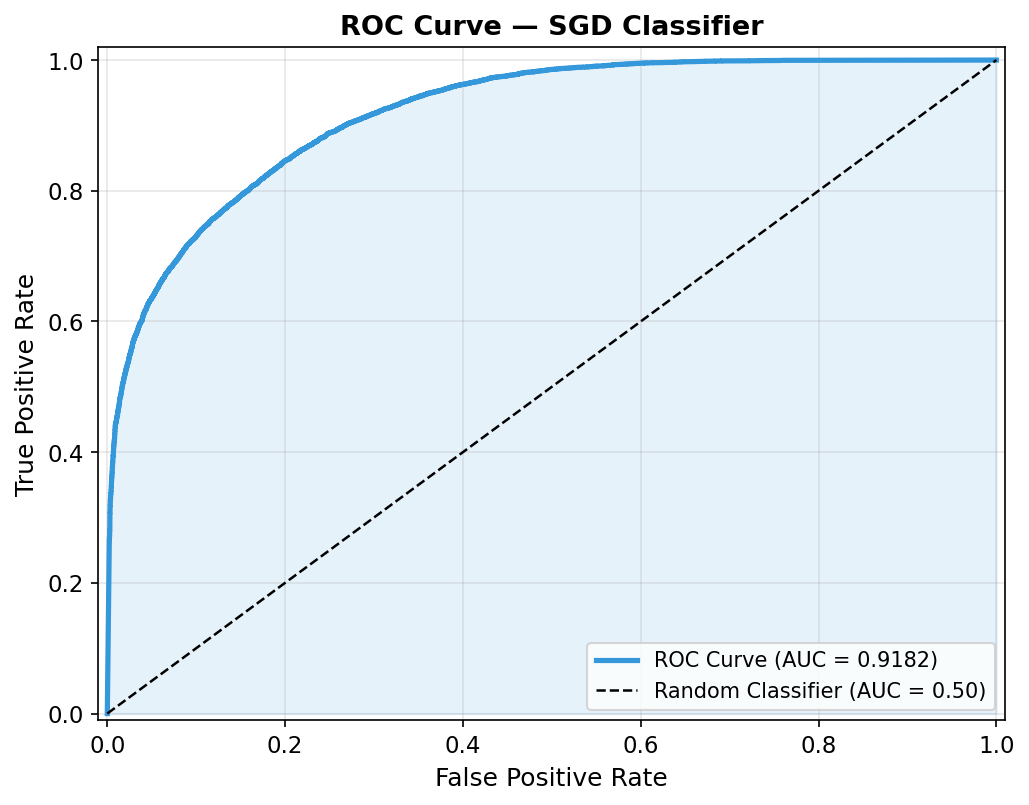

In [7]:
plot_roc_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

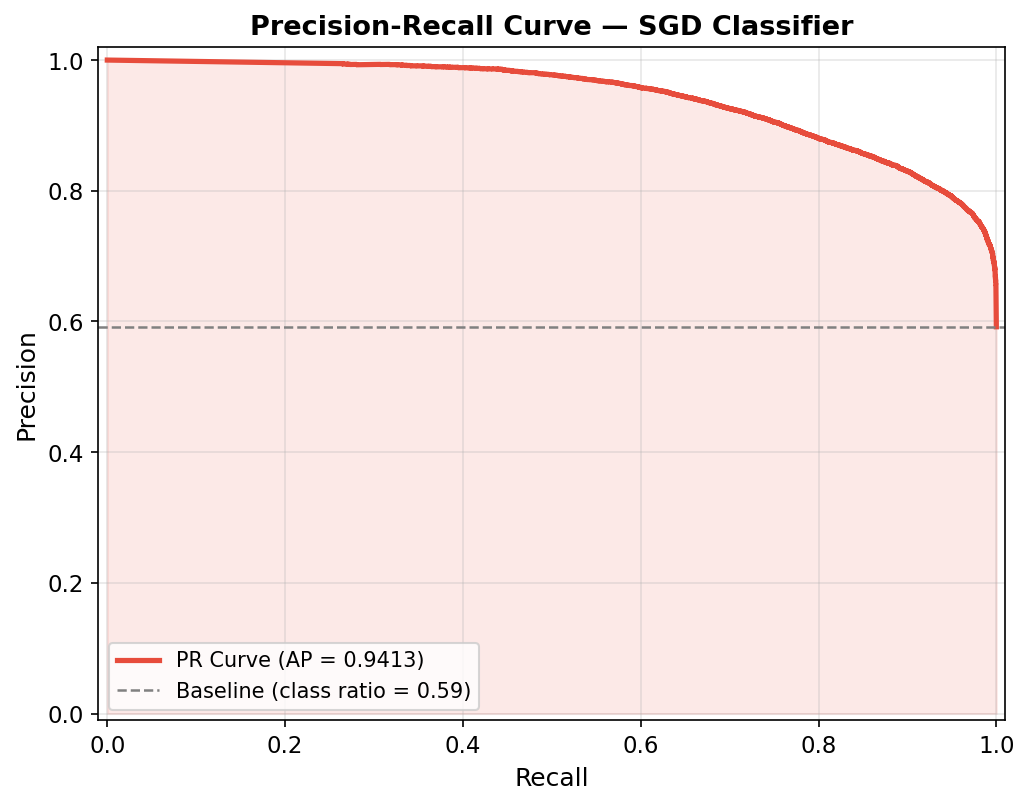

In [8]:
plot_pr_curve(y_test, y_prob, MODEL_NAME, FIGURES_DIR)

## Regularisation Path (alpha)

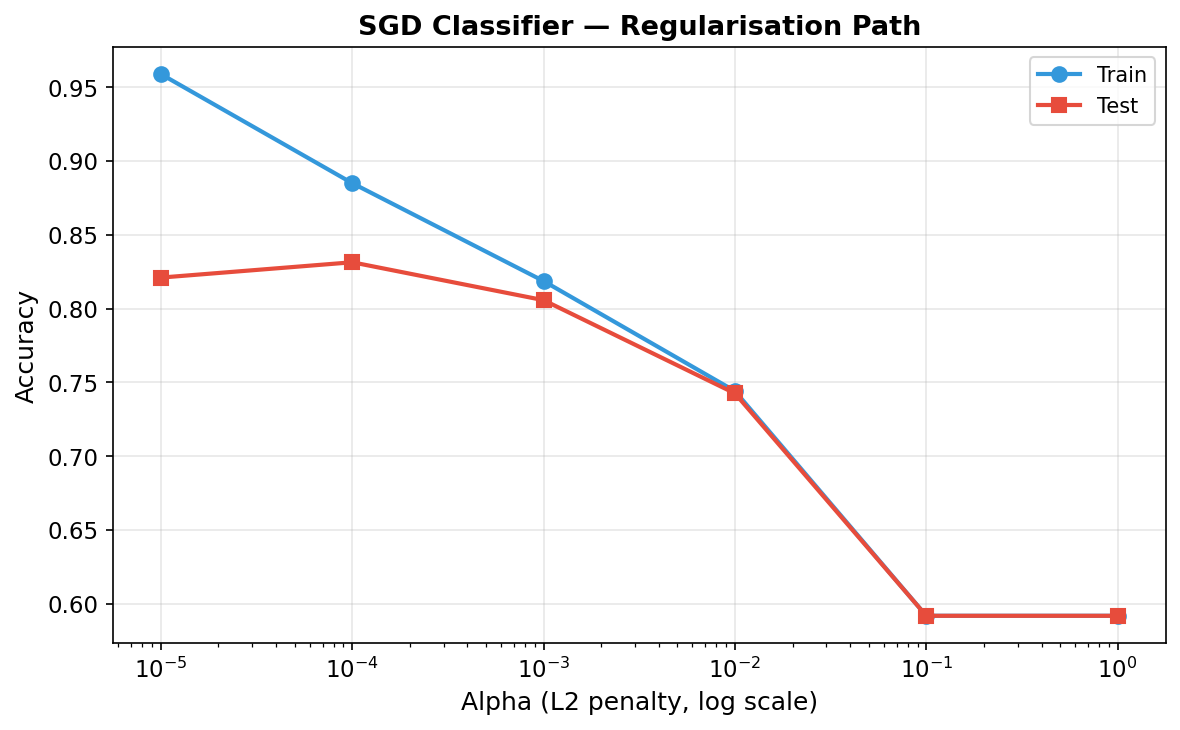

In [9]:
from sklearn.base import clone
alphas = [1e-5, 1e-4, 1e-3, 0.01, 0.1, 1.0]
tr_a, te_a = [], []
for a in alphas:
    m = SGDClassifier(loss='modified_huber', alpha=a, max_iter=100, random_state=42, n_jobs=-1)
    m.fit(X_tr, y_train)
    tr_a.append(accuracy_score(y_train, m.predict(X_tr)))
    te_a.append(accuracy_score(y_test, m.predict(X_te)))

fig, ax = plt.subplots(figsize=(8, 5))
ax.semilogx(alphas, tr_a, 'o-', color='#3498db', lw=2, ms=7, label='Train')
ax.semilogx(alphas, te_a, 's-', color='#e74c3c', lw=2, ms=7, label='Test')
ax.set_xlabel('Alpha (L2 penalty, log scale)')
ax.set_ylabel('Accuracy')
ax.set_title('SGD Classifier — Regularisation Path')
ax.legend(fontsize=10); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(os.path.join(FIGURES_DIR, 'sgd_reg_path.png'), dpi=150, bbox_inches='tight')
plt.show()